In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("File_HWG_ready.csv", sep=";")

df.head()

C:\Users\Ivan\AppData\Local\Temp\ipykernel_10340\453536004.py:4: DtypeWarning: Columns (10,17,18,22,23,24,27) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("File_HWG_ready.csv", sep=";")


,PaymentDate,Channel,Subchannel,Product,Rate,Age,TargetGroup,SourceMarket,Dependents,EmployedSince,...,EXT_FLAG2,EXT_FLAG3,EXT_SCORE4,EXT_VM_HIT,EXT_V_HIT,DEFAULTED,EXT_SP,RATE1,RATE2,PREV_DEFAULT
0,01.08.2022,1,1,A,130,22,Extended,A1,0.0,01.01.2020,...,NaN,0.0,NaN,NaN,NaN,0,0,0.0,0.0,0
1,01.08.2022,1,1,B,"186,25",41,Extended,A1,0.0,01.01.2014,...,NaN,0.0,NaN,NaN,NaN,1,0,0.0,0.0,0
2,01.08.2022,1,1,C,280,42,Extended,A1,0.0,01.01.2020,...,1.0,0.0,NaN,NaN,NaN,0,0,0.0,0.0,0
3,01.08.2022,1,1,B,"186,25",33,Extended,A1,0.0,01.01.2016,...,NaN,0.0,NaN,NaN,NaN,1,0,0.0,0.0,0
4,01.08.2022,1,1,A,130,55,Extended,A2,2.0,01.01.2021,...,NaN,0.0,NaN,NaN,NaN,1,0,0.0,0.0,0


In [3]:
# Größe des Datensatzes
print(df.shape)

# Datentypen
print(df.dtypes)

# Fehlende Werte in Prozent
fehlende_werte = df.isna().mean().mul(100).sort_values(ascending=False)
print(fehlende_werte)

# Vollständig identische Zeilen
print("Duplikate:", df.duplicated().sum())

(162747, 38)
PaymentDate        object
Channel             int64
Subchannel          int64
Product            object
Rate               object
Age                 int64
TargetGroup        object
SourceMarket       object
Dependents        float64
EmployedSince      object
EmployedFor        object
ETP                object
PEP                object
FillUp             object
NewCustomer        object
EXT_ATTRIBUTE      object
EXT_ESCALATION     object
EXT_CODE           object
EXT_FLAG           object
EXT_SCORE         float64
EXT_SCORE2        float64
EXT_SCORE3        float64
EXT_TYP            object
EXT_TYP2           object
EXT_TYP3           object
EXT_FEATURE        object
EXT_CUSTOM         object
EXT_CUSTOM2        object
EXT_FLAG2         float64
EXT_FLAG3         float64
EXT_SCORE4        float64
EXT_VM_HIT        float64
EXT_V_HIT         float64
DEFAULTED           int64
EXT_SP              int64
RATE1             float64
RATE2             float64
PREV_DEFAULT        int64

In [ ]:
## Schritt 3: Korrektur der Datentypen

**Ziel:** Sicherstellen, dass die Attribute `PaymentDate` und `Rate` im richtigen Datenformat vorliegen.

- `PaymentDate`: Umwandlung von Text in ein Datumsformat.
- `Rate`: Umwandlung von Text mit Dezimalkomma in einen numerischen Wert.

Der Originaldatensatz bleibt unverändert. Alle Änderungen erfolgen in einer Kopie (`df_clean`).

In [4]:
# Kopie des Originaldatensatzes erstellen
df_clean = df.copy()

# PaymentDate: Text in Datum umwandeln
df_clean["PaymentDate"] = pd.to_datetime(
    df_clean["PaymentDate"],
    format="%d.%m.%Y",
    errors="coerce"
)

# Rate: Dezimalkomma durch Dezimalpunkt ersetzen
df_clean["Rate"] = pd.to_numeric(
    df_clean["Rate"].astype("string").str.replace(",", ".", regex=False),
    errors="coerce"
)

print("SCHRITT 3: DATENTYPEN KORRIGIEREN")
print("=" * 50)
print("Die Umwandlung wurde durchgeführt.")
print("Der Originaldatensatz bleibt unverändert.")

SCHRITT 3: DATENTYPEN KORRIGIEREN
Die Umwandlung wurde durchgeführt.
Der Originaldatensatz bleibt unverändert.


In [5]:
print("=" * 60)
print("ERGEBNIS: ÜBERPRÜFUNG DER DATENTYPEN")
print("=" * 60)

# Vorher-Nachher-Vergleich
vergleich = pd.DataFrame({
    "Datentyp vorher": df[["PaymentDate", "Rate"]].dtypes.astype(str),
    "Datentyp nachher": df_clean[["PaymentDate", "Rate"]].dtypes.astype(str),
    "Fehlende Werte vorher": df[["PaymentDate", "Rate"]].isna().sum(),
    "Fehlende Werte nachher": df_clean[["PaymentDate", "Rate"]].isna().sum()
})

display(vergleich)

print("\nBEISPIEL: ERSTE 5 DATENSÄTZE NACH DER UMWANDLUNG")
display(df_clean[["PaymentDate", "Rate"]].head())

print("\nINTERPRETATION:")
print("- PaymentDate sollte jetzt den Datentyp datetime64[ns] besitzen.")
print("- Rate sollte jetzt einen numerischen Datentyp besitzen.")
print("- Zusätzliche fehlende Werte können auf ungültige Eingaben hinweisen.")

ERGEBNIS: ÜBERPRÜFUNG DER DATENTYPEN


,Datentyp vorher,Datentyp nachher,Fehlende Werte vorher,Fehlende Werte nachher
PaymentDate,object,datetime64[ns],0,0
Rate,object,Float64,0,0



BEISPIEL: ERSTE 5 DATENSÄTZE NACH DER UMWANDLUNG


,PaymentDate,Rate
0,2022-08-01,130.0
1,2022-08-01,186.25
2,2022-08-01,280.0
3,2022-08-01,186.25
4,2022-08-01,130.0



INTERPRETATION:
- PaymentDate sollte jetzt den Datentyp datetime64[ns] besitzen.
- Rate sollte jetzt einen numerischen Datentyp besitzen.
- Zusätzliche fehlende Werte können auf ungültige Eingaben hinweisen.


In [ ]:
## Schritt 4: Analyse fehlender Werte

**Ziel:** Identifikation und Bewertung fehlender Werte im Datensatz.

Folgende Fragen werden untersucht:

- Welche Attribute enthalten fehlende Werte?
- Wie viele Werte fehlen pro Attribut?
- Wie hoch ist der prozentuale Anteil?
- Welche Attribute sind besonders stark betroffen?

**Vorgehen:** Fehlende Werte werden zunächst analysiert und dokumentiert. Eine Löschung oder Ersetzung erfolgt erst nach fachlicher Bewertung.

In [7]:
# Datenqualitätsbericht erstellen
missing_report = pd.DataFrame({
    "Fehlende Werte": df_clean.isna().sum(),
    "Anteil (%)": (df_clean.isna().mean() * 100).round(2)
})

# Nach dem höchsten Anteil sortieren
missing_report = missing_report.sort_values(
    by="Anteil (%)",
    ascending=False
)

print("=" * 65)
print("SCHRITT 4: ANALYSE FEHLENDER WERTE")
print("=" * 65)

print(f"Anzahl Datensätze: {len(df_clean):,}")
print(f"Anzahl Attribute: {df_clean.shape[1]}")
print(f"Attribute mit fehlenden Werten: {(missing_report['Fehlende Werte'] > 0).sum()}")

print("\nERGEBNIS: FEHLENDE WERTE PRO ATTRIBUT")
display(missing_report)

SCHRITT 4: ANALYSE FEHLENDER WERTE
Anzahl Datensätze: 162,747
Anzahl Attribute: 38
Attribute mit fehlenden Werten: 17

ERGEBNIS: FEHLENDE WERTE PRO ATTRIBUT


,Fehlende Werte,Anteil (%)
EXT_V_HIT,159189,97.81
EXT_VM_HIT,159189,97.81
EXT_FLAG2,152774,93.87
EXT_SCORE4,112411,69.07
EXT_TYP,62781,38.58
EXT_TYP2,62781,38.58
EXT_TYP3,62781,38.58
EXT_CUSTOM2,62747,38.55
EXT_SCORE2,12586,7.73
EXT_SCORE3,12586,7.73


In [9]:
def bewerte_fehlende_werte(anteil):
    if anteil == 0:
        return "Keine fehlenden Werte"
    elif anteil <= 5:
        return "Geringer Anteil"
    elif anteil <= 30:
        return "Mittlerer Anteil"
    else:
        return "Hoher Anteil"

missing_report["Bewertung"] = missing_report[
    "Anteil (%)"
].apply(bewerte_fehlende_werte)

print("=" * 65)
print("ERGEBNIS: BEWERTUNG DER DATENVOLLSTÄNDIGKEIT")
print("=" * 65)

display(missing_report)

ERGEBNIS: BEWERTUNG DER DATENVOLLSTÄNDIGKEIT


,Fehlende Werte,Anteil (%),Bewertung
EXT_V_HIT,159189,97.81,Hoher Anteil
EXT_VM_HIT,159189,97.81,Hoher Anteil
EXT_FLAG2,152774,93.87,Hoher Anteil
EXT_SCORE4,112411,69.07,Hoher Anteil
EXT_TYP,62781,38.58,Hoher Anteil
EXT_TYP2,62781,38.58,Hoher Anteil
EXT_TYP3,62781,38.58,Hoher Anteil
EXT_CUSTOM2,62747,38.55,Hoher Anteil
EXT_SCORE2,12586,7.73,Mittlerer Anteil
EXT_SCORE3,12586,7.73,Mittlerer Anteil


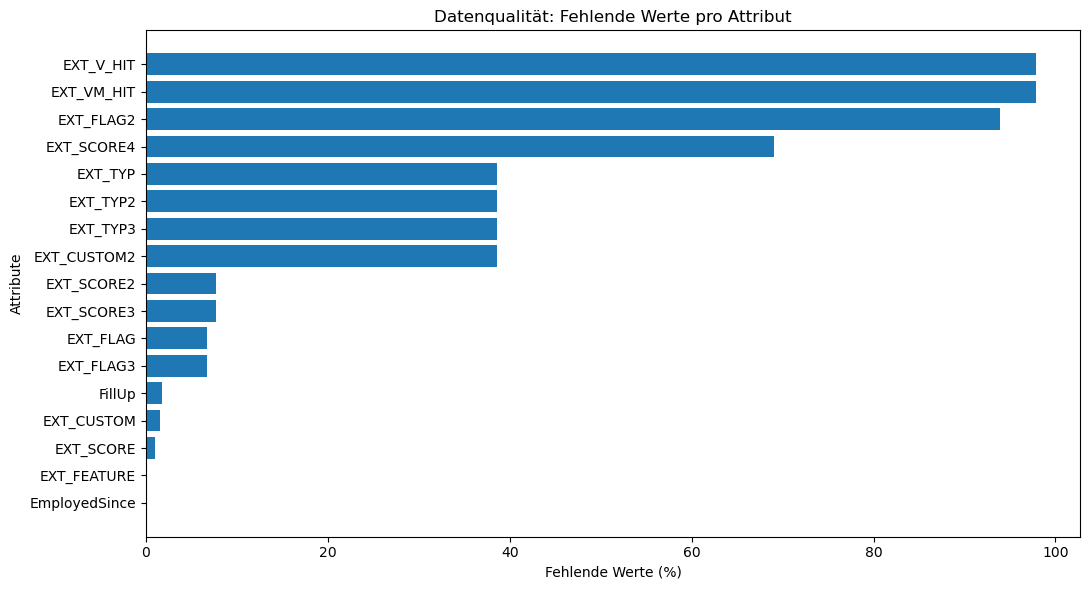

In [11]:
import matplotlib.pyplot as plt

# Nur Attribute mit fehlenden Werten
missing_plot = missing_report[
    missing_report["Fehlende Werte"] > 0
]

plt.figure(figsize=(11, 6))

plt.barh(
    missing_plot.index,
    missing_plot["Anteil (%)"]
)

plt.xlabel("Fehlende Werte (%)")
plt.ylabel("Attribute")
plt.title("Datenqualität: Fehlende Werte pro Attribut")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [12]:
missing_report.to_csv(
    "04_Bericht_Fehlende_Werte.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig"
)

print("Datenqualitätsbericht wurde erfolgreich gespeichert.")

Datenqualitätsbericht wurde erfolgreich gespeichert.


In [ ]:
## Schritt 5: Untersuchung von Duplikaten

**Ziel:** Identifikation und Analyse vollständig identischer Datensätze.

Dabei untersuchen wir:
- Wie viele doppelte Datensätze existieren?
- Welche Datensätze sind betroffen?
- Wie groß ist der Anteil der Duplikate am gesamten Datensatz?
- Sollten diese Datensätze entfernt werden?

**Hinweis:** Duplikate werden zunächst nur untersucht und nicht automatisch gelöscht.

In [13]:
print("=" * 65)
print("SCHRITT 5: UNTERSUCHUNG VON DUPLIKATEN")
print("=" * 65)

# Anzahl der Datensätze
gesamt = len(df_clean)

# Anzahl zusätzlicher identischer Zeilen
anzahl_duplikate = df_clean.duplicated().sum()

# Anteil in Prozent
anteil = (anzahl_duplikate / gesamt) * 100

print(f"Gesamtzahl der Datensätze: {gesamt:,}")
print(f"Anzahl zusätzlicher Duplikate: {anzahl_duplikate}")
print(f"Anteil der Duplikate: {anteil:.4f} %")

SCHRITT 5: UNTERSUCHUNG VON DUPLIKATEN
Gesamtzahl der Datensätze: 162,747
Anzahl zusätzlicher Duplikate: 4
Anteil der Duplikate: 0.0025 %


In [14]:
# Alle Zeilen anzeigen, die zu Duplikatgruppen gehören
duplikate = df_clean[
    df_clean.duplicated(keep=False)
]

print("=" * 65)
print("ERGEBNIS: IDENTISCHE DATENSÄTZE")
print("=" * 65)

print(f"Anzahl betroffener Zeilen: {len(duplikate)}")

display(duplikate)

ERGEBNIS: IDENTISCHE DATENSÄTZE
Anzahl betroffener Zeilen: 8


,PaymentDate,Channel,Subchannel,Product,Rate,Age,TargetGroup,SourceMarket,Dependents,EmployedSince,...,EXT_FLAG2,EXT_FLAG3,EXT_SCORE4,EXT_VM_HIT,EXT_V_HIT,DEFAULTED,EXT_SP,RATE1,RATE2,PREV_DEFAULT
69962,2024-02-01,0,5,A,140.0,23,Extended,A1,0.0,01.06.2021,...,NaN,0.0,NaN,NaN,NaN,0,0,0.0,0.0,0
69974,2024-02-01,0,5,A,140.0,23,Extended,A1,0.0,01.06.2021,...,NaN,0.0,NaN,NaN,NaN,0,0,0.0,0.0,0
78209,2024-04-01,0,6,C,301.25,38,Extended,A1,0.0,01.08.2010,...,NaN,0.0,NaN,NaN,NaN,0,0,0.0,0.0,0
80306,2024-04-01,0,6,C,301.25,38,Extended,A1,0.0,01.08.2010,...,NaN,0.0,NaN,NaN,NaN,0,0,0.0,0.0,0
84108,2024-05-01,0,6,A,140.0,23,Focus,A1,0.0,01.12.2022,...,NaN,0.0,NaN,NaN,NaN,1,0,0.0,0.0,0
85925,2024-05-01,0,6,A,140.0,23,Focus,A1,0.0,01.12.2022,...,NaN,0.0,NaN,NaN,NaN,1,0,0.0,0.0,0
94102,2024-07-01,0,2,A,140.0,22,Extended,A1,0.0,01.01.2023,...,NaN,0.0,NaN,NaN,NaN,0,0,0.0,0.0,0
94129,2024-07-01,0,2,A,140.0,22,Extended,A1,0.0,01.01.2023,...,NaN,0.0,NaN,NaN,NaN,0,0,0.0,0.0,0


In [15]:
print("=" * 65)
print("INTERPRETATION DER DUPLIKATANALYSE")
print("=" * 65)

if anzahl_duplikate == 0:
    print("Es wurden keine vollständig identischen Zeilen gefunden.")
else:
    print(f"Es wurden {anzahl_duplikate} zusätzliche identische Zeilen erkannt.")
    print(f"Das entspricht {anteil:.4f} % aller Datensätze.")
    print()
    print("Bewertung:")
    print("- Der Anteil der Duplikate ist sehr gering.")
    print("- Identische Merkmale bedeuten nicht zwingend doppelte Kunden.")
    print("- Die Datensätze bleiben vorerst erhalten.")
    print("- Eine Entfernung erfolgt erst nach fachlicher Prüfung.")

INTERPRETATION DER DUPLIKATANALYSE
Es wurden 4 zusätzliche identische Zeilen erkannt.
Das entspricht 0.0025 % aller Datensätze.

Bewertung:
- Der Anteil der Duplikate ist sehr gering.
- Identische Merkmale bedeuten nicht zwingend doppelte Kunden.
- Die Datensätze bleiben vorerst erhalten.
- Eine Entfernung erfolgt erst nach fachlicher Prüfung.


In [ ]:
## Schritt 6: Untersuchung auffälliger Werte und Ausreißer

**Ziel:** Identifikation ungewöhnlicher oder potenziell fehlerhafter Werte.

Folgende Prüfungen werden durchgeführt:

- Statistische Untersuchung numerischer Attribute
- Identifikation negativer Kreditraten
- Prüfung ungewöhnlicher Altersangaben
- Identifikation statistischer Ausreißer mithilfe des Interquartilsabstands (IQR)

**Hinweis:** Auffällige Werte werden dokumentiert und nicht automatisch entfernt.

In [19]:
print("=" * 65)
print("ERGEBNIS: PRÜFUNG NEGATIVER KREDITRATEN")
print("=" * 65)

negative_raten = df_clean[df_clean["Rate"] < 0]

print(f"Anzahl negativer Raten: {len(negative_raten)}")

if len(negative_raten) > 0:
    print("\nBetroffene Datensätze:")
    display(negative_raten[["PaymentDate", "Rate", "Product"]].head(20))
else:
    print("Keine negativen Kreditraten festgestellt.")

ERGEBNIS: PRÜFUNG NEGATIVER KREDITRATEN
Anzahl negativer Raten: 0
Keine negativen Kreditraten festgestellt.


In [20]:
print("=" * 65)
print("ERGEBNIS: PRÜFUNG DER ALTERSANGABEN")
print("=" * 65)

auffaelliges_alter = df_clean[
    (df_clean["Age"] < 18) |
    (df_clean["Age"] > 100)
]

print(f"Anzahl auffälliger Altersangaben: {len(auffaelliges_alter)}")

if len(auffaelliges_alter) > 0:
    display(auffaelliges_alter[["Age", "Product", "DEFAULTED"]].head(20))
else:
    print("Keine Altersangaben außerhalb des Prüfbereichs gefunden.")

ERGEBNIS: PRÜFUNG DER ALTERSANGABEN
Anzahl auffälliger Altersangaben: 0
Keine Altersangaben außerhalb des Prüfbereichs gefunden.


In [29]:
df_clean.to_csv(
    "File_HWG_cleaned.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

print("CSV-Datei erfolgreich gespeichert!")

CSV-Datei erfolgreich gespeichert!


In [30]:
bericht = pd.DataFrame({
    "Attribut": df_clean.columns,
    "Datentyp": df_clean.dtypes.astype(str).values,
    "Fehlende Werte": df_clean.isna().sum().values,
    "Fehlende Werte (%)": (
        df_clean.isna().mean() * 100
    ).round(2).values
})

with pd.ExcelWriter("Datenqualitaetsbericht.xlsx") as writer:
    bericht.to_excel(
        writer,
        sheet_name="Datenqualität",
        index=False
    )

    ausreisser_report.to_excel(
        writer,
        sheet_name="Ausreißer",
        index=False
    )

print("Excel-Bericht erfolgreich gespeichert!")

Excel-Bericht erfolgreich gespeichert!
